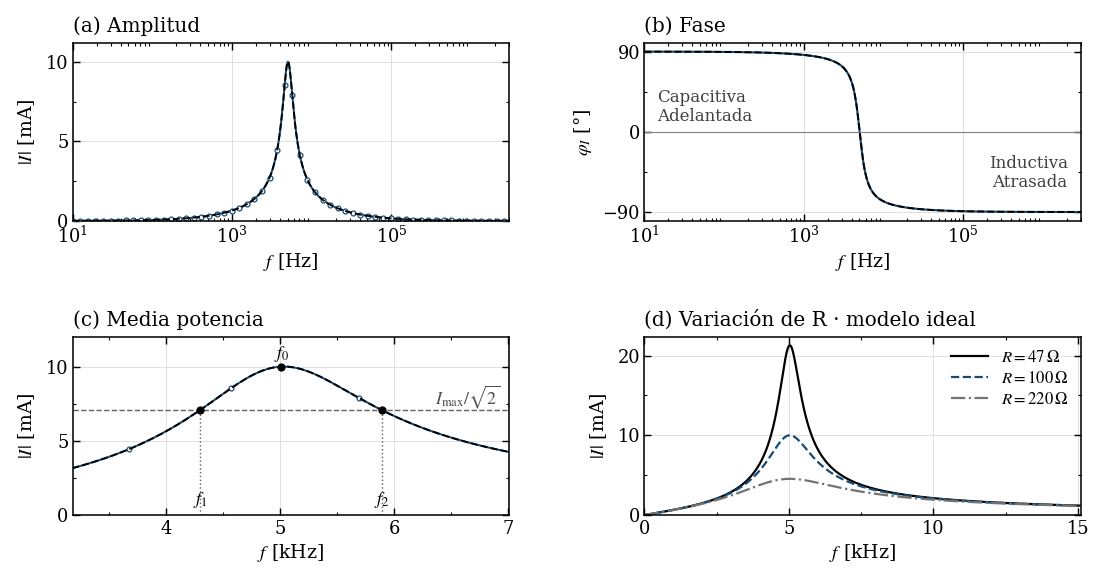

LTspice
f0 = 5011.87 Hz; Imax = 9.996 mA
f1 = 4299.00 Hz; f2 = 5891.93 Hz; Δf = 1592.94 Hz; Q = 3.146


In [56]:
%matplotlib inline

from pathlib import Path
import re

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter


# ============================================================
# 1. CONFIGURACIÓN
# ============================================================

R = 100.0          # Resistencia [ohm]
L = 10e-3          # Inductancia [H]
C = 100e-9         # Capacitancia [F]
VIN = 1.0          # Amplitud AC de entrada [V]

F_MIN = 10.0
F_MAX = 3e6        # Tu captura: .ac dec 200 10 3000k

# Para usar los datos exportados de LTspice:
ARCHIVO = (
    r"C:\Users\pazli\Documents\Github"
    r"\Py-Projects\SomePhysics\CircuitosAC.txt"
)

# Para mostrar únicamente el modelo teórico, usá:
# ARCHIVO = None

# None detecta una única corriente I(...).
# Si exportaste varias, indicá cuál usar: "I(R)" o "I(R1)".
TRAZA = None

# Activá esto si el sentido de referencia de la corriente
# agrega 180° a la fase.
INVERTIR_CORRIENTE = False

AZUL = "#235789"
VERDE = "#168A82"
NARANJA = "#CF6438"
TEXTO = "#202C39"
GRIS = "#6F7B87"

ESTILO = {
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.edgecolor": "#BCC5CE",
    "axes.labelcolor": TEXTO,
    "text.color": TEXTO,
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "grid.color": "#DCE2E8",
    "grid.linewidth": 0.65,
    "legend.frameon": False,
    "mathtext.fontset": "dejavusans",
}


# ============================================================
# 2. MODELO ANALÍTICO
# ============================================================

def corriente_teorica(f, resistencia):
    """Corriente compleja del RLC serie, en amperes."""
    omega = 2 * np.pi * np.asarray(f)

    impedancia = (
        resistencia
        + 1j * (omega * L - 1 / (omega * C))
    )

    return VIN / impedancia


def valores_teoricos(resistencia):
    """Resonancia, cortes, ancho de banda y factor de calidad."""
    raiz = np.sqrt(resistencia**2 + 4 * L / C)

    f0 = 1 / (2 * np.pi * np.sqrt(L * C))
    f1 = (raiz - resistencia) / (4 * np.pi * L)
    f2 = (raiz + resistencia) / (4 * np.pi * L)

    ancho = resistencia / (2 * np.pi * L)

    return {
        "f0": f0,
        "Imax": VIN / resistencia,
        "f1": f1,
        "f2": f2,
        "BW": ancho,
        "Q": f0 / ancho,
    }


# ============================================================
# 3. LECTOR DE EXPORTACIONES DE LTspice
# ============================================================

def separar_campos(linea, separador):
    """
    Separa columnas sin romper pares complejos como:
    (parte_real, parte_imaginaria).
    """
    campos = []
    campo = []
    profundidad = 0
    comillas = False

    for caracter in linea.strip():
        if caracter == '"':
            comillas = not comillas
            continue

        if not comillas:
            profundidad += (
                int(caracter == "(")
                - int(caracter == ")")
            )

        if separador == " ":
            es_separador = caracter.isspace()
        else:
            es_separador = caracter == separador

        if es_separador and profundidad == 0 and not comillas:
            if campo or separador != " ":
                campos.append("".join(campo).strip())
            campo = []
        else:
            campo.append(caracter)

    campos.append("".join(campo).strip())

    return campos


def numero_ac(celda):
    """
    Admite:
      número
      (real, imaginario)
      (magnitud_dB, fase_grados)
      (magnitud_lineal, fase_grados°)
    """
    texto = celda.strip().replace("−", "-")

    if texto.startswith("(") and texto.endswith(")"):
        numeros = texto[1:-1].split(",")

        if len(numeros) != 2:
            raise ValueError(
                f"Par complejo no reconocido: {celda}"
            )

        def limpiar(valor):
            valor = valor.lower()

            for unidad in ("db", "deg", "°", "â"):
                valor = valor.replace(unidad, "")

            valor = valor.replace("1.#inf", "inf")

            return float(valor.strip())

        a, b = map(limpiar, numeros)

        if "db" in texto.lower():
            magnitud = 10 ** (a / 20)
            return magnitud * np.exp(1j * np.deg2rad(b))

        if "°" in texto or "deg" in texto.lower():
            return a * np.exp(1j * np.deg2rad(b))

        return complex(a, b)

    return complex(float(texto.replace(",", ".")))


def leer_ltspice(ruta):
    """
    Lee una corriente compleja I(...), o magnitud y fase.

    CSV sencillo admitido:
        frecuencia_Hz,corriente_A,fase_deg

    También admite:
        corriente_mA
        mag(I(R1)) y ph(I(R1))
        exportaciones con tabulaciones
        pares complejos o pares dB/fase

    Exportar un único paso de .step por archivo.
    """
    ruta = Path(ruta).expanduser()

    if not ruta.is_file():
        raise FileNotFoundError(
            f"No encuentro el archivo:\n{ruta}\n\n"
            "Revisá el nombre y la extensión, o usá "
            "ARCHIVO = None para mostrar el modelo teórico."
        )

    datos = ruta.read_bytes()

    if datos.startswith((b"\xff\xfe", b"\xfe\xff")):
        texto = datos.decode("utf-16")
    else:
        try:
            texto = datos.decode("utf-8-sig")
        except UnicodeDecodeError:
            texto = datos.decode("cp1252")

    lineas = [
        linea.strip()
        for linea in texto.splitlines()
        if linea.strip()
    ]

    if any(
        "step information" in linea.lower()
        for linea in lineas
    ):
        raise ValueError(
            "El archivo contiene pasos de .step. "
            "Exportá un único paso por archivo."
        )

    lineas = [
        linea
        for linea in lineas
        if not linea.startswith(("#", "*"))
    ]

    if not lineas:
        raise ValueError("El archivo está vacío.")

    cabecera = lineas[0]

    separador = next(
        (
            caracter
            for caracter in ("\t", ";", ",")
            if caracter in cabecera
        ),
        " ",
    )

    nombres = separar_campos(cabecera, separador)

    claves = [
        nombre.lower().replace(" ", "")
        for nombre in nombres
    ]

    columnas_f = [
        i
        for i, nombre in enumerate(claves)
        if nombre.startswith(("freq", "frec"))
        or nombre in ("f", "f_hz")
    ]

    if not columnas_f:
        raise ValueError(
            "No encuentro la columna de frecuencia.\n"
            f"Columnas disponibles: {nombres}"
        )

    filas = []

    for numero, linea in enumerate(lineas[1:], start=2):
        fila = separar_campos(linea, separador)

        if len(fila) != len(nombres):
            raise ValueError(
                f"Fila {numero}: tiene {len(fila)} campos; "
                f"se esperaban {len(nombres)}."
            )

        filas.append(fila)

    def columna(indice):
        return np.array(
            [numero_ac(fila[indice]) for fila in filas],
            dtype=complex,
        )

    frecuencias = columna(columnas_f[0]).real

    columnas_i = [
        i
        for i, nombre in enumerate(claves)
        if re.fullmatch(r"i\(.+\)", nombre)
    ]

    if TRAZA is not None:
        traza_elegida = TRAZA.lower().replace(" ", "")

        columnas_i = [
            i
            for i in columnas_i
            if claves[i] == traza_elegida
        ]

    if len(columnas_i) > 1:
        raise ValueError(
            "Hay varias corrientes en el archivo. "
            'Configurá TRAZA, por ejemplo TRAZA = "I(R1)".'
        )

    if columnas_i:
        indice = columnas_i[0]

        if not all(
            fila[indice].strip().startswith("(")
            for fila in filas
        ):
            raise ValueError(
                "La corriente I(...) debe estar exportada "
                "como par complejo, o como magnitud y fase "
                "en columnas separadas."
            )

        corriente = columna(indice)

    else:
        def buscar_columna(opciones, prefijo):
            encontradas = [
                i
                for i, nombre in enumerate(claves)
                if nombre in opciones
                or nombre.startswith(prefijo)
            ]

            if len(encontradas) != 1:
                raise ValueError(
                    "No puedo identificar una columna única "
                    f"de {prefijo}.\nColumnas: {nombres}"
                )

            return encontradas[0]

        indice_magnitud = buscar_columna(
            {"corriente_a", "corriente_ma", "i_a", "i_ma"},
            "mag(i(",
        )

        indice_fase = buscar_columna(
            {"fase_deg", "phase_deg"},
            "ph(i(",
        )

        magnitud = columna(indice_magnitud).real
        fase = columna(indice_fase).real

        if claves[indice_magnitud] in {
            "corriente_ma", "i_ma"
        }:
            magnitud = magnitud / 1000

        if np.any(magnitud < 0):
            raise ValueError(
                "La magnitud lineal no puede ser negativa. "
                "Revisá si exportaste valores en dB."
            )

        corriente = (
            magnitud * np.exp(1j * np.deg2rad(fase))
        )

    if INVERTIR_CORRIENTE:
        corriente = -corriente

    return frecuencias, corriente


# ============================================================
# 4. ANÁLISIS DE LOS DATOS
# ============================================================

def analizar(f, corriente):
    """
    Obtiene el máximo muestreado y los dos cortes.

    Los cortes se interpolan linealmente en amplitud
    frente a log10(f).
    """
    f = np.asarray(f, dtype=float)
    corriente = np.asarray(corriente, dtype=complex)

    if len(f) < 5 or len(f) != len(corriente):
        raise ValueError(
            "Se necesitan al menos cinco frecuencias "
            "y sus corrientes."
        )

    if not (
        np.all(np.isfinite(f))
        and np.all(np.isfinite(corriente))
    ):
        raise ValueError(
            "Hay valores vacíos, infinitos o no numéricos."
        )

    if np.any(f <= 0):
        raise ValueError(
            "Todas las frecuencias deben ser positivas."
        )

    orden = np.argsort(f)
    f = f[orden]
    corriente = corriente[orden]

    if np.any(np.diff(f) <= 0):
        raise ValueError(
            "Hay frecuencias repetidas. "
            "Exportá un único paso de .step."
        )

    amplitud = np.abs(corriente)
    indice_pico = int(np.argmax(amplitud))

    if (
        indice_pico == 0
        or indice_pico == len(f) - 1
        or amplitud[indice_pico] <= 0
    ):
        raise ValueError(
            "El barrido debe contener el pico "
            "y ambos lados de la campana."
        )

    nivel = amplitud[indice_pico] / np.sqrt(2)

    cambios = np.flatnonzero(
        (amplitud[:-1] - nivel)
        * (amplitud[1:] - nivel)
        <= 0
    )

    izquierda = cambios[cambios < indice_pico]
    derecha = cambios[cambios >= indice_pico]

    if not len(izquierda) or not len(derecha):
        raise ValueError(
            "Falta un cruce a −3 dB. "
            "Ampliá el barrido de frecuencia."
        )

    def interpolar_cruce(indice):
        a, b = amplitud[indice:indice + 2]

        if a == b:
            return float(
                np.sqrt(f[indice] * f[indice + 1])
            )

        fraccion = (nivel - a) / (b - a)

        log_f = (
            np.log10(f[indice])
            + fraccion
            * np.log10(f[indice + 1] / f[indice])
        )

        return float(10 ** log_f)

    f1 = interpolar_cruce(izquierda[-1])
    f2 = interpolar_cruce(derecha[0])

    fase = np.rad2deg(
        np.unwrap(np.angle(corriente))
    )

    f0 = float(f[indice_pico])
    ancho = f2 - f1

    resultados = {
        "f0": f0,
        "Imax": float(amplitud[indice_pico]),
        "f1": f1,
        "f2": f2,
        "BW": ancho,
        "Q": f0 / ancho,
    }

    return f, amplitud, fase, resultados
%matplotlib inline

import matplotlib.ticker as ticker
from matplotlib.lines import Line2D


# Tamaño final previsto dentro del informe.
ANCHO_CM = 17.8
ALTO_CM = 10.0

ESTILO_COMPACTO = {
    "font.family": "DejaVu Serif",
    "mathtext.fontset": "stix",
    "font.size": 8.5,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "axes.titleweight": "normal",
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "axes.linewidth": 0.7,
    "axes.edgecolor": "black",
    "axes.labelcolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "text.color": "black",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": True,
    "axes.spines.right": True,
    "legend.frameon": False,
    "figure.dpi": 160,
}


def eje_compacto(ax, log=False):
    ax.tick_params(
        which="both",
        direction="in",
        top=True,
        right=True,
        length=3,
        width=0.65,
        pad=2,
    )
    ax.tick_params(
        which="minor",
        length=1.5,
        width=0.5,
    )

    ax.grid(
        which="major",
        color="0.88",
        linewidth=0.45,
    )
    ax.set_axisbelow(True)

    ax.yaxis.set_major_locator(
        ticker.MaxNLocator(
            nbins=3,
            steps=[1, 2, 2.5, 5, 10],
        )
    )
    ax.yaxis.set_minor_locator(
        ticker.AutoMinorLocator(2)
    )

    if log:
        ax.set_xscale("log")

        # Etiquetas cada dos décadas para evitar amontonamientos.
        exponentes = np.arange(
            int(np.ceil(np.log10(f.min()))),
            int(np.floor(np.log10(f.max()))) + 1,
            2,
        )
        ticks = 10.0 ** exponentes

        if len(ticks) >= 2:
            ax.xaxis.set_major_locator(
                ticker.FixedLocator(ticks)
            )
        else:
            ax.xaxis.set_major_locator(
                ticker.LogLocator(base=10)
            )

        ax.xaxis.set_major_formatter(
            ticker.LogFormatterMathtext(base=10)
        )

    else:
        ax.xaxis.set_major_locator(
            ticker.MaxNLocator(
                nbins=4,
                steps=[1, 2, 2.5, 5, 10],
            )
        )
        ax.xaxis.set_minor_locator(
            ticker.AutoMinorLocator(2)
        )


# ============================================================
# CARGAR Y ANALIZAR LOS DATOS
# ============================================================

plt.close("all")

teorico = valores_teoricos(R)

f_modelo = np.unique(np.r_[
    np.geomspace(F_MIN, F_MAX, 6000),
    [
        valor
        for valor in (
            teorico["f1"],
            teorico["f0"],
            teorico["f2"],
        )
        if F_MIN <= valor <= F_MAX
    ],
])

usar_datos = ARCHIVO is not None

if usar_datos:
    f, corriente = leer_ltspice(ARCHIVO)
else:
    f = f_modelo
    corriente = corriente_teorica(f, R)

f, amplitud, fase, resultados = analizar(f, corriente)

if not usar_datos:
    resultados = teorico.copy()

f_ref = np.geomspace(f.min(), f.max(), 6000)
I_ref = corriente_teorica(f_ref, R)

fase_ref = np.rad2deg(
    np.unwrap(np.angle(I_ref))
)

azul = "#174a73"


# ============================================================
# UNA FIGURA CON CUATRO PANELES
# ============================================================

with plt.rc_context(ESTILO_COMPACTO):
    fig, ejes = plt.subplots(
        2,
        2,
        figsize=(ANCHO_CM / 2.54, ALTO_CM / 2.54),
    )

    fig.subplots_adjust(
        left=0.087,
        right=0.986,
        bottom=0.115,
        top=0.865,
        wspace=0.31,
        hspace=0.65,
    )

    a, b, c, d = ejes.ravel()

    # Curvas de amplitud: barrido completo y detalle.
    for ax, factor in ((a, 1), (c, 1000)):
        if usar_datos:
            # Se conserva toda la línea de datos.
            # Solo se espacian los marcadores.
            ax.plot(
                f / factor,
                amplitud * 1000,
                color=azul,
                linewidth=0.9,
                marker="o",
                markersize=2.2,
                markerfacecolor="white",
                markeredgewidth=0.55,
                markevery=max(1, len(f) // 55),
            )

            ax.plot(
                f_ref / factor,
                np.abs(I_ref) * 1000,
                color="black",
                linestyle="--",
                linewidth=0.85,
            )

        else:
            ax.plot(
                f / factor,
                amplitud * 1000,
                color="black",
                linewidth=1.0,
            )

    # --------------------------------------------------------
    # (a) Amplitud en todo el barrido
    # --------------------------------------------------------

    a.set_title("(a) Amplitud", loc="left", pad=5)
    a.set_ylabel(r"$|I|$ [mA]")
    a.set_xlabel(r"$f$ [Hz]", labelpad=2)

    eje_compacto(a, log=True)

    a.set_xlim(f.min(), f.max())
    a.set_ylim(0, amplitud.max() * 1000 * 1.12)

    # --------------------------------------------------------
    # (b) Fase
    # --------------------------------------------------------

    b.plot(
        f,
        fase,
        color=azul if usar_datos else "black",
        linewidth=0.95,
    )

    if usar_datos:
        b.plot(
            f_ref,
            fase_ref,
            "k--",
            linewidth=0.85,
        )

    b.axhline(0, color="0.5", linewidth=0.5)

    b.set_title("(b) Fase", loc="left", pad=5)
    b.set_ylabel(r"$\varphi_I$ [°]")
    b.set_xlabel(r"$f$ [Hz]", labelpad=2)

    eje_compacto(b, log=True)

    b.set_xlim(f.min(), f.max())
    b.set_ylim(
        min(-100, fase.min() - 5),
        max(100, fase.max() + 5),
    )
    b.set_yticks([-90, 0, 90])

    # Mostrar la interpretación cuando la referencia de
    # corriente coincide con el sentido usado en el modelo.
    if abs(fase[np.argmax(amplitud)]) < 90:
        b.text(
            0.03,
            0.64,
            "Capacitiva\nAdelantada",
            transform=b.transAxes,
            fontsize=7.5,
            va="center",
            color="0.25",
        )

        b.text(
            0.97,
            0.27,
            "Inductiva\nAtrasada",
            transform=b.transAxes,
            fontsize=7.5,
            ha="right",
            va="center",
            color="0.25",
        )

    # --------------------------------------------------------
    # (c) Detalle de los cortes
    # --------------------------------------------------------

    f0, f1, f2 = (
        resultados[clave] / 1000
        for clave in ("f0", "f1", "f2")
    )

    pico = resultados["Imax"] * 1000
    nivel = pico / np.sqrt(2)
    ancho = f2 - f1

    c.axhline(
        nivel,
        color="0.4",
        linestyle="--",
        linewidth=0.65,
    )

    c.vlines(
        [f1, f2],
        0,
        nivel,
        color="0.4",
        linestyle=":",
        linewidth=0.65,
    )

    c.plot(
        [f1, f2, f0],
        [nivel, nivel, pico],
        "ko",
        markersize=2.7,
    )

    c.annotate(
        r"$f_0$",
        (f0, pico),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        fontsize=8,
    )

    for x, etiqueta in (
        (f1, r"$f_1$"),
        (f2, r"$f_2$"),
    ):
        c.text(
            x,
            0.03,
            etiqueta,
            transform=c.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=8,
        )

    c.set_title("(c) Media potencia", loc="left", pad=5)
    c.set_ylabel(r"$|I|$ [mA]")
    c.set_xlabel(r"$f$ [kHz]", labelpad=2)

    eje_compacto(c)

    c.set_xlim(
        max(f.min() / 1000, f1 - 0.7 * ancho),
        min(f.max() / 1000, f2 + 0.7 * ancho),
    )

    c.set_ylim(
        0,
        max(pico, teorico["Imax"] * 1000) * 1.2,
    )

    c.text(
        0.98,
        nivel / c.get_ylim()[1] + 0.035,
        r"$I_{\max}/\sqrt{2}$",
        transform=c.transAxes,
        ha="right",
        fontsize=8,
        color="0.3",
    )

    # --------------------------------------------------------
    # (d) Comparación teórica de resistencias
    # --------------------------------------------------------

    for resistencia, color, trazo in (
        (47, "black", "-"),
        (100, azul, "--"),
        (220, "0.45", "-."),
    ):
        d.plot(
            f_modelo / 1000,
            np.abs(
                corriente_teorica(f_modelo, resistencia)
            ) * 1000,
            color=color,
            linestyle=trazo,
            linewidth=1.0,
            label=rf"$R={resistencia}\,\Omega$",
        )

    d.set_title(
        "(d) Variación de R · modelo ideal",
        loc="left",
        pad=5,
    )
    d.set_ylabel(r"$|I|$ [mA]")
    d.set_xlabel(r"$f$ [kHz]", labelpad=2)

    eje_compacto(d)

    d.set_xlim(
        0,
        min(F_MAX / 1000, 3 * teorico["f0"] / 1000),
    )
    d.set_ylim(bottom=0)

    d.legend(
        loc="upper right",
        fontsize=7.5,
        handlelength=2.2,
        labelspacing=0.25,
        borderaxespad=0.3,
    )

    # --------------------------------------------------------
    # Leyenda compartida de los paneles (a), (b) y (c)
    # --------------------------------------------------------

    if usar_datos:
        elementos = [
            Line2D(
                [], [],
                color=azul,
                linewidth=0.9,
                marker="o",
                markersize=2.7,
                markerfacecolor="white",
                markeredgewidth=0.55,
                label="LTspice",
            ),
            Line2D(
                [], [],
                color="black",
                linestyle="--",
                linewidth=0.85,
                label="Modelo ideal",
            ),
        ]
    else:
        elementos = [
            Line2D(
                [], [],
                color="black",
                linewidth=1,
                label="Modelo ideal · sin datos importados",
            )
        ]

fig.savefig(
    "RLC_resonancia.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.05,
    facecolor="white",
)

plt.show()


# Resultados fuera de la figura.
print(
    "LTspice" if usar_datos
    else "Modelo analítico ideal"
)

print(
    f"f0 = {resultados['f0']:.2f} Hz; "
    f"Imax = {resultados['Imax'] * 1000:.3f} mA"
)

print(
    f"f1 = {resultados['f1']:.2f} Hz; "
    f"f2 = {resultados['f2']:.2f} Hz; "
    f"Δf = {resultados['BW']:.2f} Hz; "
    f"Q = {resultados['Q']:.3f}"
)

if usar_datos and abs(fase[np.argmax(amplitud)]) > 90:
    print(
        "Revisá la referencia de corriente con "
        "INVERTIR_CORRIENTE: la fase cerca del pico "
        "sugiere el sentido opuesto."
    )

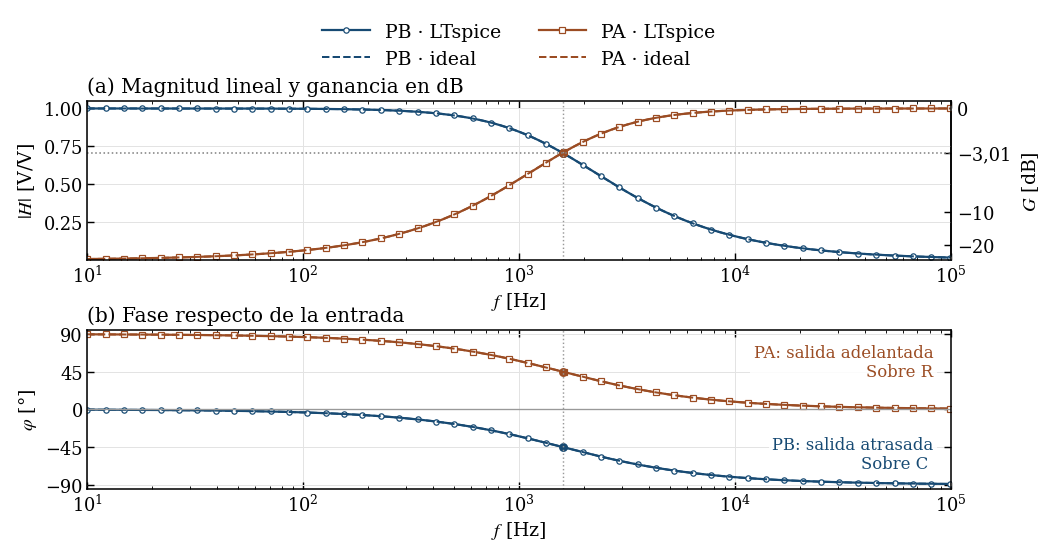

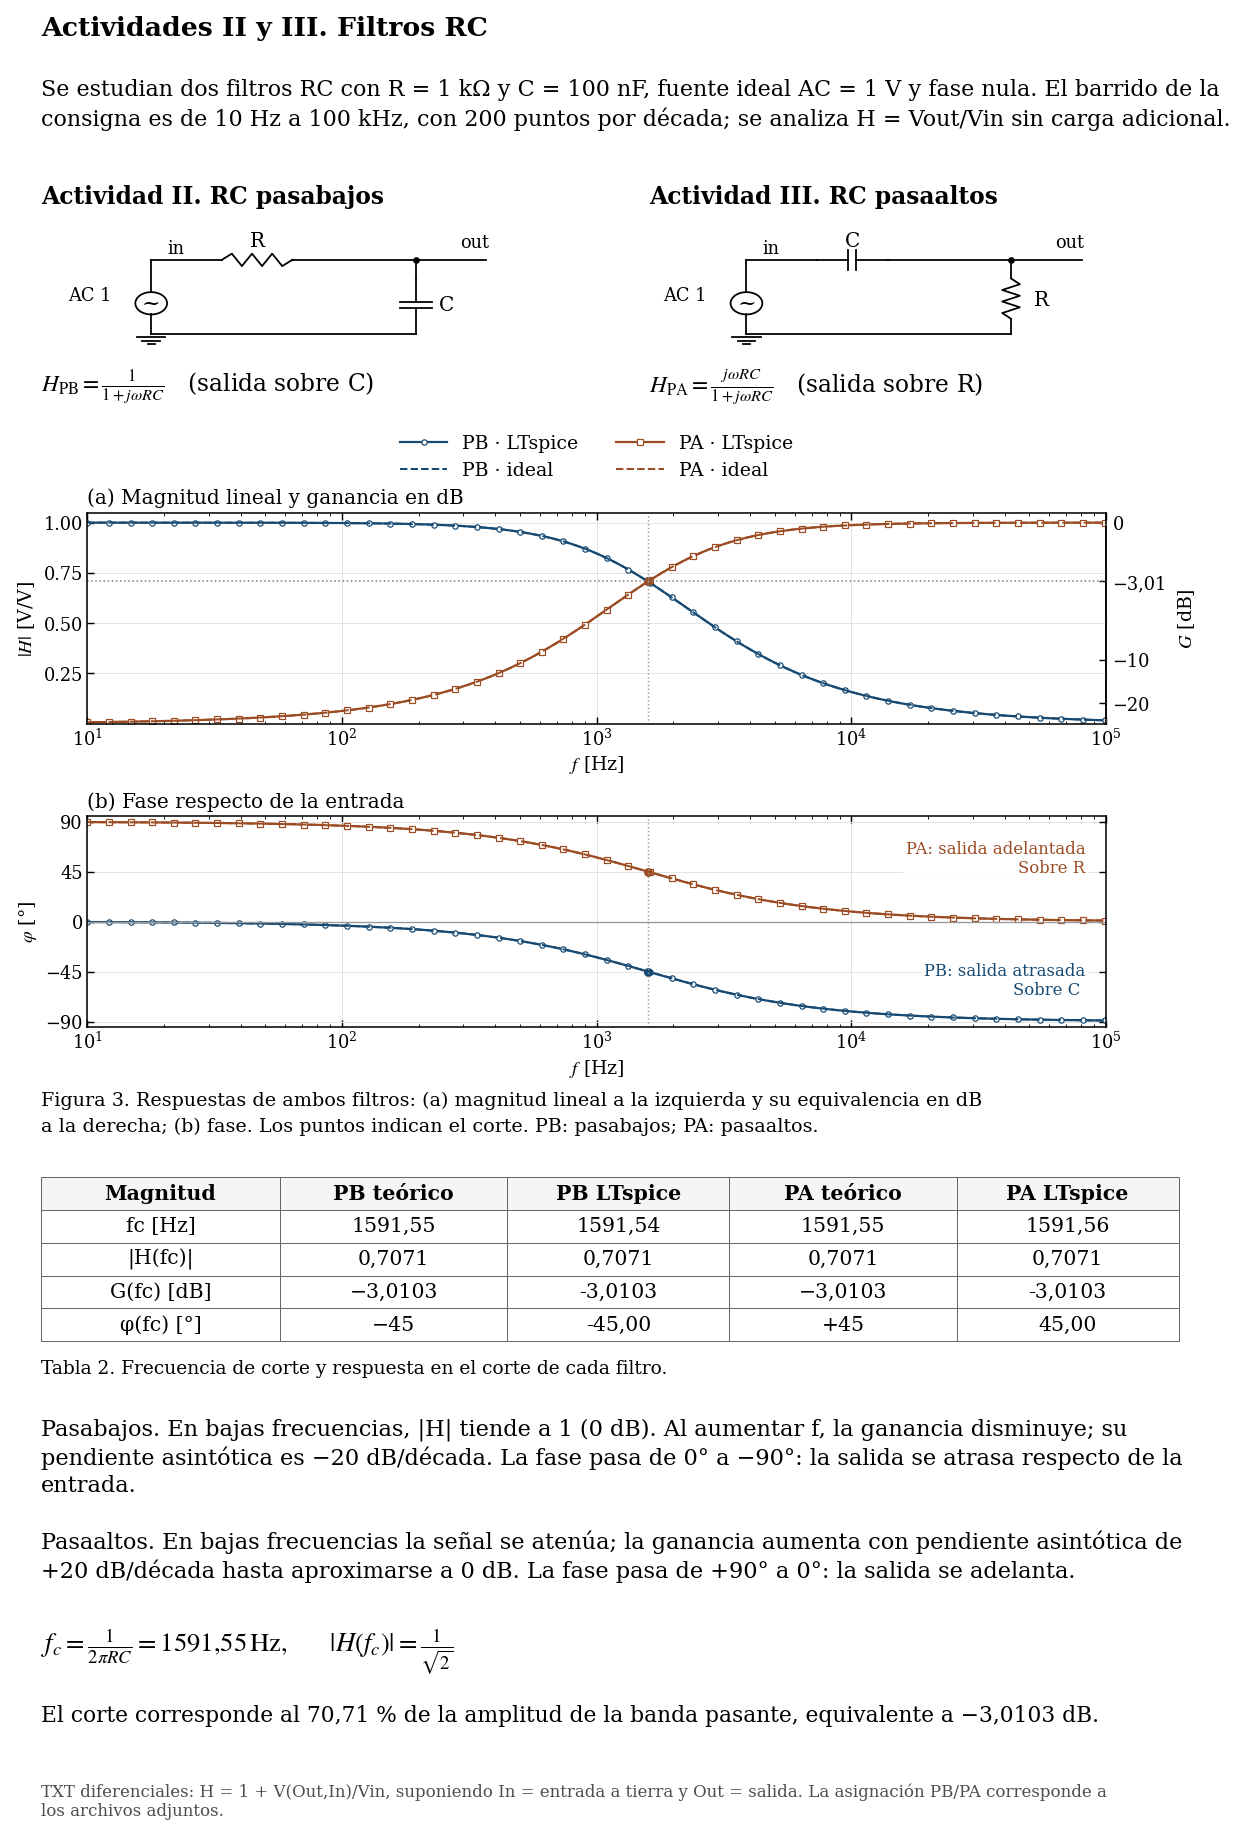

Filtro   Origen         fc [Hz]    |H(fc)|   G(fc) [dB]   fase [°]
PB       LTspice         1591.54    0.7071     -3.0103     -45.00
PA       LTspice         1591.56    0.7071     -3.0103      45.00

PB: ganancia a 10 Hz = -0.000171 dB
PA: ganancia a 100000 Hz = -0.001100 dB

Carpeta actual: C:\Users\pazli\Documents\Github\Py-Projects\SomePhysics
Imagen guardada: RC_pasabajos_pasaaltos.png
Carilla guardada: Actividades_II_III_RC_una_carilla.pdf


In [78]:
# %% 1. Configuración
"""Filtros RC: gráficos con etiquetas de fase y una carilla A4.

Dependencias: numpy y matplotlib.
Funciona en Jupyter y como archivo .py.

Los PNG y PDF se guardan en la carpeta actual, sin crear subcarpetas.

Interpretación de tus exportaciones:
    V(Out,In) = Vout - Vin

Se supone:
    In = entrada referida a tierra.
    Out = salida.
    Vin = AC 1 V con fase cero.

Entonces:
    H = Vout/Vin = 1 + V(Out,In)/Vin

Bajo ese supuesto, tus archivos se asignan como se indica abajo.
"""

from pathlib import Path
import textwrap

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker

# Mostrar las figuras dentro de Jupyter.
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass


R = 1000.0
C = 100e-9
VIN_AC = 1.0

F_MIN, F_MAX = 10.0, 100_000.0

# Asignación para TUS archivos diferenciales, bajo el supuesto indicado.
# Si reexportás archivos, revisá esta asignación.
ARCHIVO_PB = (
    r"C:\Users\pazli\Documents\Github\Py-Projects"
    r"\SomePhysics\pasaaltos.txt"
)

ARCHIVO_PA = (
    r"C:\Users\pazli\Documents\Github\Py-Projects"
    r"\SomePhysics\pasabajos.txt"
)

# Para mostrar solamente el modelo ideal:
# ARCHIVO_PB = None
# ARCHIVO_PA = None

GUARDAR_PNG = True
GUARDAR_PDF = True
MOSTRAR = True

NOMBRE_PNG = "RC_pasabajos_pasaaltos.png"
NOMBRE_PDF = "Actividades_II_III_RC_una_carilla.pdf"

AZUL = "#174a73"
NARANJA = "#9b4c23"

ESTILO = {
    "font.family": "DejaVu Serif",
    "mathtext.fontset": "stix",
    "font.size": 8.5,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.7,
    "axes.edgecolor": "black",
    "axes.labelcolor": "black",
    "text.color": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.spines.top": True,
    "axes.spines.right": True,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "legend.frameon": False,
    "figure.dpi": 160,
    "pdf.fonttype": 42,
}


# %% 2. Lectura de los archivos

def separar(linea, separador):
    """Separa columnas sin romper pares complejos ni campos entre comillas."""
    campos = []
    campo = []
    profundidad = 0
    comillas = False

    for ch in linea.strip():
        if ch == '"':
            comillas = not comillas
            continue

        if not comillas:
            profundidad += int(ch == "(") - int(ch == ")")

        es_separador = (
            ch.isspace() if separador == " " else ch == separador
        )

        if es_separador and profundidad == 0 and not comillas:
            if campo or separador != " ":
                campos.append("".join(campo).strip())
            campo = []
        else:
            campo.append(ch)

    campos.append("".join(campo).strip())
    return campos


def numero_ac(celda):
    """Lee escalares, pares (real,imag) y pares (dB,fase°)."""
    s = celda.strip().replace("−", "-")

    if s.startswith("(") and s.endswith(")"):
        pares = s[1:-1].split(",")

        if len(pares) != 2:
            raise ValueError(f"Par AC no reconocido: {celda}")

        def limpiar(t):
            t = t.lower()

            for unidad in ("db", "deg", "°", "â"):
                t = t.replace(unidad, "")

            return float(t.replace("1.#inf", "inf").strip())

        a, b = map(limpiar, pares)

        if "db" in s.lower():
            return 10 ** (a / 20) * np.exp(1j * np.deg2rad(b))

        if "°" in s or "deg" in s.lower():
            return a * np.exp(1j * np.deg2rad(b))

        return complex(a, b)

    return complex(float(s.replace(",", ".")))


def leer_transferencia(ruta):
    """Lee frecuencia y una traza AC compleja.

    Admite:
        V(Out,In)
        V(In,Out)
        V(out)/V(in)
        V(out)

    Las tensiones se normalizan por VIN_AC, con fase de entrada cero.
    """
    p = Path(ruta).expanduser()

    if not p.is_file():
        raise FileNotFoundError(
            f"No encuentro el archivo:\n{p}\n\n"
            "Revisá ARCHIVO_PB y ARCHIVO_PA."
        )

    raw = p.read_bytes()

    if raw.startswith((b"\xff\xfe", b"\xfe\xff")):
        texto = raw.decode("utf-16")
    else:
        try:
            texto = raw.decode("utf-8-sig")
        except UnicodeDecodeError:
            texto = raw.decode("cp1252")

    lineas = [
        s.strip() for s in texto.splitlines()
        if s.strip()
    ]

    if any("step information" in s.lower() for s in lineas):
        raise ValueError(
            "Exportá un solo paso de .step por archivo."
        )

    if len(lineas) < 2:
        raise ValueError(
            "El archivo no contiene encabezados y datos."
        )

    sep = next(
        (s for s in ("\t", ";", ",") if s in lineas[0]),
        " ",
    )

    nombres = separar(lineas[0], sep)
    claves = [
        s.lower().replace(" ", "")
        for s in nombres
    ]

    filas = [
        separar(s, sep)
        for s in lineas[1:]
    ]

    if (
        len(nombres) != 2
        or any(len(fila) != 2 for fila in filas)
    ):
        raise ValueError(
            "Exportá frecuencia y una única traza compleja por archivo."
        )

    if not claves[0].startswith(("freq", "frec")):
        raise ValueError(
            f"La primera columna debe ser la frecuencia: {nombres}"
        )

    f = np.array(
        [float(fila[0]) for fila in filas],
        dtype=float,
    )

    if not all(fila[1].startswith("(") for fila in filas):
        raise ValueError(
            "La traza debe incluir magnitud y fase, "
            "o parte real e imaginaria."
        )

    v = np.array(
        [numero_ac(fila[1]) for fila in filas],
        dtype=complex,
    )

    if claves[1] == "v(out,in)":
        H = 1 + v / VIN_AC

    elif claves[1] == "v(in,out)":
        H = 1 - v / VIN_AC

    elif claves[1] == "v(out)/v(in)":
        H = v

    elif claves[1] == "v(out)":
        H = v / VIN_AC

    else:
        raise ValueError(
            f"Traza no reconocida: {nombres[1]}"
        )

    return f, H


# %% 3. Modelo y análisis

def transferencia(f, tipo):
    """Función de transferencia ideal sin carga adicional."""
    x = 2 * np.pi * np.asarray(f) * R * C

    if tipo == "PB":
        return 1 / (1 + 1j * x)

    if tipo == "PA":
        return 1j * x / (1 + 1j * x)

    raise ValueError("El tipo debe ser 'PB' o 'PA'.")


def analizar(f, H, tipo):
    """Calcula el corte interpolando sobre log10(f)."""
    f = np.asarray(f, dtype=float)
    H = np.asarray(H, dtype=complex)

    if len(f) < 5 or f.shape != H.shape:
        raise ValueError(
            "Se necesitan al menos cinco pares frecuencia/transferencia."
        )

    if (
        not np.all(np.isfinite(f))
        or not np.all(np.isfinite(H))
        or np.any(f <= 0)
    ):
        raise ValueError(
            "Hay frecuencias no positivas o datos no finitos."
        )

    orden = np.argsort(f)
    f, H = f[orden], H[orden]

    if np.any(np.diff(f) <= 0):
        raise ValueError(
            "Hay frecuencias repetidas; revisá los pasos de .step."
        )

    amp = np.abs(H)

    if np.any(amp <= 0):
        raise ValueError(
            "La transferencia debe ser no nula para calcular sus dB."
        )

    fase = np.rad2deg(np.unwrap(np.angle(H)))
    nivel = 1 / np.sqrt(2)
    pendientes = np.diff(amp)

    sentido = (
        pendientes < 0 if tipo == "PB"
        else pendientes > 0
    )

    indices = np.flatnonzero(
        ((amp[:-1] - nivel) * (amp[1:] - nivel) <= 0)
        & sentido
    )

    if not len(indices):
        raise ValueError(
            f"{tipo}: el barrido no cruza |H| = 1/√2. "
            "Revisá el rango y la traza exportada."
        )

    cortes = []

    for i in indices:
        t = (
            (nivel - amp[i])
            / (amp[i + 1] - amp[i])
        )

        corte = 10 ** (
            np.log10(f[i])
            + t * np.log10(f[i + 1] / f[i])
        )

        cortes.append(corte)

    cortes = np.unique(np.round(cortes, 9))

    if len(cortes) != 1:
        raise ValueError(
            f"{tipo}: se detectaron varios cortes. "
            "Revisá la traza exportada."
        )

    fc = float(cortes[0])

    phi = float(
        np.interp(
            np.log10(fc),
            np.log10(f),
            fase,
        )
    )

    mediciones = {
        "fc": fc,
        "magnitud": nivel,
        "db": 20 * np.log10(nivel),
        "fase": phi,
    }

    return f, H, mediciones


def cargar_datos():
    if min(R, C, VIN_AC, F_MIN) <= 0 or F_MAX <= F_MIN:
        raise ValueError(
            "Revisá los componentes y el intervalo de frecuencias."
        )

    fc = 1 / (2 * np.pi * R * C)

    if not F_MIN < fc < F_MAX:
        raise ValueError(
            "El barrido debe contener la frecuencia de corte."
        )

    fmodelo = np.unique(
        np.r_[np.geomspace(F_MIN, F_MAX, 6000), fc]
    )

    resultados = {}

    for tipo, archivo in (
        ("PB", ARCHIVO_PB),
        ("PA", ARCHIVO_PA),
    ):
        if archivo is None:
            f = fmodelo
            H = transferencia(fmodelo, tipo)
        else:
            f, H = leer_transferencia(archivo)

        f, H, mediciones = analizar(f, H, tipo)

        if archivo is None:
            mediciones = {
                "fc": fc,
                "magnitud": 1 / np.sqrt(2),
                "db": 20 * np.log10(1 / np.sqrt(2)),
                "fase": -45.0 if tipo == "PB" else 45.0,
            }

        resultados[tipo] = {
            "f": f,
            "H": H,
            "mediciones": mediciones,
            "importado": archivo is not None,
        }

    return resultados


# %% 4. Gráficos y etiquetas

def lineal_a_db(y):
    return 20 * np.log10(
        np.maximum(np.asarray(y), 1e-300)
    )


def db_a_lineal(db):
    return 10 ** (np.asarray(db) / 20)


def dibujar_paneles(fig, datos, rect):
    """Dibuja magnitud y fase con etiquetas en ambas figuras."""
    left, bottom, width, height = rect
    altura_panel = height * 0.41

    a = fig.add_axes([
        left,
        bottom + height - altura_panel,
        width,
        altura_panel,
    ])

    b = fig.add_axes([
        left,
        bottom,
        width,
        altura_panel,
    ])

    handles = []
    colores = {"PB": AZUL, "PA": NARANJA}

    minimo = np.inf
    ymax = 1.05
    fase_min, fase_max = -95, 95

    fmin = min(d["f"].min() for d in datos.values())
    fmax = max(d["f"].max() for d in datos.values())

    for tipo in ("PB", "PA"):
        d = datos[tipo]
        f, H = d["f"], d["H"]
        color = colores[tipo]

        amp = np.abs(H)
        fase = np.rad2deg(np.unwrap(np.angle(H)))

        minimo = min(minimo, amp.min())
        ymax = max(ymax, amp.max() * 1.04)
        fase_min = min(fase_min, fase.min() - 5)
        fase_max = max(fase_max, fase.max() + 5)

        if d["importado"]:
            estilo_simulacion = {
                "color": color,
                "lw": 1,
                "marker": "o" if tipo == "PB" else "s",
                "ms": 2.4,
                "mfc": "white",
                "mew": 0.55,
                "markevery": max(1, len(f) // 45),
            }

            h, = a.plot(
                f,
                amp,
                label=f"{tipo} · LTspice",
                **estilo_simulacion,
            )

            b.plot(f, fase, **estilo_simulacion)
            handles.append(h)

            fr = np.geomspace(f.min(), f.max(), 3000)
            Hr = transferencia(fr, tipo)

            h, = a.plot(
                fr,
                np.abs(Hr),
                color=color,
                ls="--",
                lw=0.9,
                label=f"{tipo} · ideal",
            )

            b.plot(
                fr,
                np.rad2deg(np.unwrap(np.angle(Hr))),
                color=color,
                ls="--",
                lw=0.9,
            )

        else:
            estilo_linea = "-" if tipo == "PB" else "--"

            h, = a.plot(
                f,
                amp,
                color=color,
                ls=estilo_linea,
                lw=1.2,
                label=f"{tipo} · modelo ideal",
            )

            b.plot(
                f,
                fase,
                color=color,
                ls=estilo_linea,
                lw=1.2,
            )

        handles.append(h)

        fc = d["mediciones"]["fc"]

        a.plot(
            fc,
            1 / np.sqrt(2),
            "o",
            color=color,
            ms=3,
        )

        b.plot(
            fc,
            d["mediciones"]["fase"],
            "o",
            color=color,
            ms=3,
        )

    # Magnitud lineal y su equivalencia exacta en dB.
    # Se evita cero porque log10(0) no está definido.
    a.set_ylim(min(1e-4, minimo / 2), ymax)
    a.set_yticks([0.25, 0.5, 0.75, 1.0])
    a.set_ylabel(r"$|H|$ [V/V]", labelpad=3)

    sec = a.secondary_yaxis(
        "right",
        functions=(lineal_a_db, db_a_lineal),
    )

    sec.set_ylabel(r"$G$ [dB]", labelpad=4)
    sec.set_yticks([0, -3.01029995664, -10, -20])
    sec.set_yticklabels(["0", "−3,01", "−10", "−20"])

    sec.tick_params(
        direction="in",
        length=3,
        width=0.65,
        pad=3,
        labelsize=8,
    )

    a.axhline(
        1 / np.sqrt(2),
        color="0.5",
        ls=":",
        lw=0.7,
    )

    a.set_title(
        "(a) Magnitud lineal y ganancia en dB",
        loc="left",
        pad=4,
    )

    b.set_title(
        "(b) Fase respecto de la entrada",
        loc="left",
        pad=4,
    )

    b.set_ylabel(r"$\varphi$ [°]", labelpad=3)
    b.set_ylim(fase_min, fase_max)
    b.set_yticks([-90, -45, 0, 45, 90])
    b.axhline(0, color="0.6", lw=0.6)

    fc_teorico = 1 / (2 * np.pi * R * C)

    for ax in (a, b):
        ax.set_xscale("log")
        ax.set_xlim(fmin, fmax)

        ax.axvline(
            fc_teorico,
            color="0.6",
            ls=":",
            lw=0.65,
        )

        ax.set_xlabel(r"$f$ [Hz]", labelpad=2)

        exponentes = np.arange(
            int(np.ceil(np.log10(fmin))),
            int(np.floor(np.log10(fmax))) + 1,
        )

        if len(exponentes) > 5:
            exponentes = exponentes[::2]

        if len(exponentes) >= 2:
            ax.xaxis.set_major_locator(
                ticker.FixedLocator(10.0 ** exponentes)
            )

            ax.xaxis.set_major_formatter(
                ticker.LogFormatterMathtext()
            )

        ax.tick_params(
            which="both",
            direction="in",
            top=True,
            right=(ax is b),
            pad=2,
            length=3,
            width=0.65,
        )

        ax.tick_params(
            which="minor",
            length=1.4,
            width=0.4,
        )

        ax.grid(
            which="major",
            color="0.89",
            lw=0.45,
        )

        ax.set_axisbelow(True)

    desplazamiento = 25 / (fig.get_figheight() * 72)

    fig.legend(
        handles=handles,
        loc="center",
        bbox_to_anchor=(
            left + width / 2,
            bottom + height + desplazamiento,
        ),
        ncol=2,
        fontsize=8.5,
        handlelength=2.5,
        columnspacing=2,
    )

    # ---------------------------------------------------------------
    # ETIQUETAS DE FASE
    # Están dentro de esta función para aparecer tanto en el gráfico
    # independiente como en la carilla.
    # ---------------------------------------------------------------
    caja = {
        "facecolor": "white",
        "edgecolor": "none",
        "alpha": 0.88,
        "pad": 1.5,
    }

    b.text(
        0.98,
        0.80,
        "PA: salida adelantada\nSobre R",
        transform=b.transAxes,
        ha="right",
        va="center",
        fontsize=7.4,
        color=NARANJA,
        linespacing=1.15,
        bbox=caja,
    )

    b.text(
        0.98,
        0.22,
        "PB: salida atrasada\nSobre C ",
        transform=b.transAxes,
        ha="right",
        va="center",
        fontsize=7.4,
        color=AZUL,
        linespacing=1.15,
        bbox=caja,
    )

    return a, b, sec


# %% 5. Esquemas

def esquema(ax, tipo):
    ax.set_xlim(-0.5, 4.3)
    ax.set_ylim(-0.25, 1.65)
    ax.axis("off")

    def linea(x1, y1, x2, y2):
        ax.plot(
            [x1, x2],
            [y1, y2],
            color="black",
            lw=0.8,
        )

    def resistor(x1, x2, y):
        pts = (
            [(x1, y)]
            + [
                (
                    x1 + (x2 - x1) * i / 7,
                    y + (0.10 if i % 2 else -0.10),
                )
                for i in range(1, 7)
            ]
            + [(x2, y)]
        )

        ax.plot(*zip(*pts), color="black", lw=0.8)

    def capacitor(x1, x2, y):
        medio = (x1 + x2) / 2

        linea(x1, y, medio - 0.045, y)
        linea(medio + 0.045, y, x2, y)
        linea(medio - 0.045, y - 0.16, medio - 0.045, y + 0.16)
        linea(medio + 0.045, y - 0.16, medio + 0.045, y + 0.16)

    ax.add_patch(
        plt.Circle(
            (0, 0.5),
            0.18,
            fill=False,
            color="black",
            lw=0.8,
        )
    )

    ax.text(
        0,
        0.5,
        "~",
        ha="center",
        va="center",
        fontsize=10,
    )

    linea(0, 0.68, 0, 1.2)
    linea(0, 0.32, 0, 0)
    linea(0, 0, 3, 0)
    linea(0, 1.2, 0.8, 1.2)

    if tipo == "PB":
        resistor(0.8, 1.6, 1.2)
        ax.text(
            1.2, 1.42, "R",
            ha="center",
            fontsize=9,
        )
    else:
        capacitor(0.8, 1.6, 1.2)
        ax.text(
            1.2, 1.42, "C",
            ha="center",
            fontsize=9,
        )

    linea(1.6, 1.2, 3, 1.2)
    linea(3, 1.2, 3, 0.9)

    if tipo == "PB":
        linea(3, 0.9, 3, 0.52)
        linea(2.82, 0.52, 3.18, 0.52)
        linea(2.82, 0.43, 3.18, 0.43)
        linea(3, 0.43, 3, 0)

        ax.text(
            3.26, 0.48, "C",
            va="center",
            fontsize=9,
        )

    else:
        pts = (
            [(3, 0.9)]
            + [
                (
                    3 + (0.1 if i % 2 else -0.1),
                    0.9 - 0.65 * i / 7,
                )
                for i in range(1, 7)
            ]
            + [(3, 0.25)]
        )

        ax.plot(*zip(*pts), color="black", lw=0.8)
        linea(3, 0.25, 3, 0)

        ax.text(
            3.26, 0.56, "R",
            va="center",
            fontsize=9,
        )

    linea(3, 1.2, 3.8, 1.2)
    ax.plot(3, 1.2, "ko", ms=2)

    ax.text(3.5, 1.4, "out", fontsize=8)
    ax.text(0.18, 1.3, "in", fontsize=8)

    for w, y in (
        (0.16, -0.04),
        (0.10, -0.10),
        (0.04, -0.16),
    ):
        linea(-w, y, w, y)

    ax.text(
        -0.45,
        0.55,
        f"AC {VIN_AC:g}",
        ha="right",
        fontsize=8,
    )


# %% 6. Carilla A4

def crear_carilla(datos):
    fig = plt.figure(
        figsize=(21 / 2.54, 29.7 / 2.54)
    )

    fig.text(
        0.07,
        0.965,
        "Actividades II y III. Filtros RC",
        fontsize=12,
        weight="bold",
    )

    intro = (
        f"Se estudian dos filtros RC con R = {R / 1000:g} kΩ "
        f"y C = {C * 1e9:g} nF, fuente ideal AC = {VIN_AC:g} V "
        "y fase nula. El barrido de la consigna es de 10 Hz a "
        "100 kHz, con 200 puntos por década; se analiza "
        "H = Vout/Vin sin carga adicional."
    )

    fig.text(
        0.07,
        0.942,
        textwrap.fill(intro, 110),
        fontsize=10,
        va="top",
        linespacing=1.35,
    )

    fig.text(
        0.07,
        0.875,
        "Actividad II. RC pasabajos",
        fontsize=10.5,
        weight="bold",
    )

    fig.text(
        0.53,
        0.875,
        "Actividad III. RC pasaaltos",
        fontsize=10.5,
        weight="bold",
    )

    esquema(
        fig.add_axes([0.12, 0.797, 0.32, 0.063]),
        "PB",
    )

    esquema(
        fig.add_axes([0.57, 0.797, 0.32, 0.063]),
        "PA",
    )

    fig.text(
        0.07,
        0.775,
        r"$H_{\rm PB}=\frac{1}{1+j\omega RC}$"
        "   (salida sobre C)",
        fontsize=10.5,
    )

    fig.text(
        0.53,
        0.775,
        r"$H_{\rm PA}=\frac{j\omega RC}{1+j\omega RC}$"
        "   (salida sobre R)",
        fontsize=10.5,
    )

    dibujar_paneles(
        fig,
        datos,
        (0.105, 0.435, 0.77, 0.275),
    )

    fig.text(
        0.07,
        0.393,
        "Figura 3. Respuestas de ambos filtros: "
        "(a) magnitud lineal a la izquierda y su equivalencia en dB",
        fontsize=8.6,
    )

    fig.text(
        0.07,
        0.379,
        "a la derecha; (b) fase. Los puntos indican el corte. "
        "PB: pasabajos; PA: pasaaltos.",
        fontsize=8.6,
    )

    fc = 1 / (2 * np.pi * R * C)

    def valor(tipo, clave, dec=2):
        d = datos[tipo]

        if not d["importado"]:
            return "—"

        return (
            f"{d['mediciones'][clave]:.{dec}f}"
            .replace(".", ",")
        )

    fc_texto = f"{fc:.2f}".replace(".", ",")

    filas = [
        [
            "fc [Hz]",
            fc_texto,
            valor("PB", "fc"),
            fc_texto,
            valor("PA", "fc"),
        ],
        [
            "|H(fc)|",
            "0,7071",
            valor("PB", "magnitud", 4),
            "0,7071",
            valor("PA", "magnitud", 4),
        ],
        [
            "G(fc) [dB]",
            "−3,0103",
            valor("PB", "db", 4),
            "−3,0103",
            valor("PA", "db", 4),
        ],
        [
            "φ(fc) [°]",
            "−45",
            valor("PB", "fase"),
            "+45",
            valor("PA", "fase"),
        ],
    ]

    at = fig.add_axes([0.07, 0.267, 0.86, 0.088])
    at.axis("off")

    tabla = at.table(
        cellText=filas,
        colLabels=[
            "Magnitud",
            "PB teórico",
            "PB LTspice",
            "PA teórico",
            "PA LTspice",
        ],
        cellLoc="center",
        colWidths=[0.21, 0.20, 0.195, 0.20, 0.195],
        bbox=[0, 0, 1, 1],
    )

    tabla.auto_set_font_size(False)
    tabla.set_fontsize(9.2)

    for (fila, columna), celda in tabla.get_celld().items():
        celda.set_edgecolor("0.4")
        celda.set_linewidth(0.45)

        if fila == 0:
            celda.set_text_props(weight="bold")
            celda.set_facecolor("0.96")

    fig.text(
        0.07,
        0.25,
        "Tabla 2. Frecuencia de corte y respuesta en el corte de cada filtro.",
        fontsize=8.4,
    )

    texto_pb = (
        "Pasabajos. En bajas frecuencias, |H| tiende a 1 (0 dB). "
        "Al aumentar f, la ganancia disminuye; su pendiente "
        "asintótica es −20 dB/década. La fase pasa de 0° a −90°: "
        "la salida se atrasa respecto de la entrada."
    )

    texto_pa = (
        "Pasaaltos. En bajas frecuencias la señal se atenúa; "
        "la ganancia aumenta con pendiente asintótica de "
        "+20 dB/década hasta aproximarse a 0 dB. "
        "La fase pasa de +90° a 0°: la salida se adelanta."
    )

    fig.text(
        0.07,
        0.226,
        textwrap.fill(texto_pb, 100),
        fontsize=10.1,
        va="top",
        linespacing=1.3,
    )

    fig.text(
        0.07,
        0.166,
        textwrap.fill(texto_pa, 100),
        fontsize=10.1,
        va="top",
        linespacing=1.3,
    )

    fc_math = f"{fc:.2f}".replace(".", "{,}")

    fig.text(
        0.07,
        0.101,
        r"$f_c=\frac{1}{2\pi RC}="
        + fc_math
        + r"\,\mathrm{Hz},\qquad |H(f_c)|=\frac{1}{\sqrt{2}}$",
        fontsize=12,
    )

    cierre = (
        "El corte corresponde al 70,71 % de la amplitud "
        "de la banda pasante, equivalente a −3,0103 dB."
    )

    fig.text(
        0.07,
        0.073,
        textwrap.fill(cierre, 103),
        fontsize=9.8,
        va="top",
    )

    if not all(d["importado"] for d in datos.values()):
        nota = (
            "—: datos de LTspice no cargados; "
            "se muestra el modelo ideal."
        )
    else:
        nota = (
            "TXT diferenciales: H = 1 + V(Out,In)/Vin, "
            "suponiendo In = entrada a tierra y Out = salida. "
            "La asignación PB/PA corresponde a los archivos adjuntos."
        )

    fig.text(
        0.07,
        0.031,
        textwrap.fill(nota, 125),
        fontsize=7.5,
        color="0.3",
        va="top",
    )

    return fig


# %% 7. Ejecución y guardado local

def ejecutar():
    datos = cargar_datos()

    with plt.rc_context(ESTILO):
        fig = plt.figure(
            figsize=(17.8 / 2.54, 8.8 / 2.54)
        )

        dibujar_paneles(
            fig,
            datos,
            (0.105, 0.15, 0.77, 0.70),
        )

        carilla = crear_carilla(datos)

        if GUARDAR_PNG:
            fig.savefig(
                NOMBRE_PNG,
                dpi=600,
                bbox_inches="tight",
                pad_inches=0.06,
                facecolor="white",
            )

        if GUARDAR_PDF:
            carilla.savefig(
                NOMBRE_PDF,
                facecolor="white",
            )

        if MOSTRAR:
            plt.show()
        else:
            plt.close(fig)
            plt.close(carilla)

    print(
        "Filtro   Origen         fc [Hz]    "
        "|H(fc)|   G(fc) [dB]   fase [°]"
    )

    for tipo, d in datos.items():
        m = d["mediciones"]
        origen = (
            "LTspice" if d["importado"]
            else "Modelo ideal"
        )

        print(
            f"{tipo:<8} {origen:<13} "
            f"{m['fc']:>9.2f}  "
            f"{m['magnitud']:>8.4f}  "
            f"{m['db']:>10.4f}  "
            f"{m['fase']:>9.2f}"
        )

    print()

    for tipo, d in datos.items():
        k = 0 if tipo == "PB" else -1
        ganancia = 20 * np.log10(abs(d["H"][k]))

        print(
            f"{tipo}: ganancia a {d['f'][k]:g} Hz "
            f"= {ganancia:.6f} dB"
        )

    if not all(d["importado"] for d in datos.values()):
        print(
            "\nLos filtros sin archivo cargado muestran "
            "predicciones teóricas."
        )

    if GUARDAR_PNG or GUARDAR_PDF:
        print(f"\nCarpeta actual: {Path.cwd()}")

    if GUARDAR_PNG:
        print("Imagen guardada:", NOMBRE_PNG)

    if GUARDAR_PDF:
        print("Carilla guardada:", NOMBRE_PDF)

    return fig, carilla, datos


if __name__ == "__main__":
    fig, carilla, resultados = ejecutar()